# # 01 · Decoder-only Transformer (GPT)
#
# The architecture behind GPT-2/3, and the starting point for almost every modern LLM.
# A stack of identical blocks, each = **causal multi-head self-attention** + **MLP**, wrapped in residual connections
# and (pre-)LayerNorm. "Causal" means token *t* may only look at tokens ≤ *t*, so the model is trained to predict the
# next token everywhere in parallel.

---

### At a glance

| | |
|---|---|
| **Family** | Decoder-only Transformer |
| **Representative models** | GPT-2/3/4, the whole LLaMA lineage |
| **Core idea** | Causal self-attention + MLP in a residual stack, trained to predict the next token. |
| **Compute / memory** | O(T²) time, KV cache grows linearly with context |
| **Dataset** | tiny-Shakespeare (char level) – see notebook 00 |
| **Runtime** | ≈ 57 s on a laptop CPU |

### What you will learn

- Implement causal multi-head attention and a pre-LN Transformer block from scratch
- Inspect parameters, the fx graph and attention maps
- Train and sample a character-level LM

> Environment: `uv sync` then `uv run jupyter lab` (kernel **LLM Architecture (uv)**). Data: `uv run python scripts/prepare_data.py`.

---

In [1]:
import math
import torch, torch.nn as nn, torch.nn.functional as F, matplotlib.pyplot as plt, numpy as np
from llmarch import *
setup_style()
set_seed(0); device = get_device(); STEPS = 1200   # same budget in every LM notebook -> comparable
data = load_text_data("char"); train, val, V = data["train"], data["val"], data["vocab_size"]
print("device:", device, "| vocab:", V)

device: cpu | vocab: 65


# ## Architecture diagram

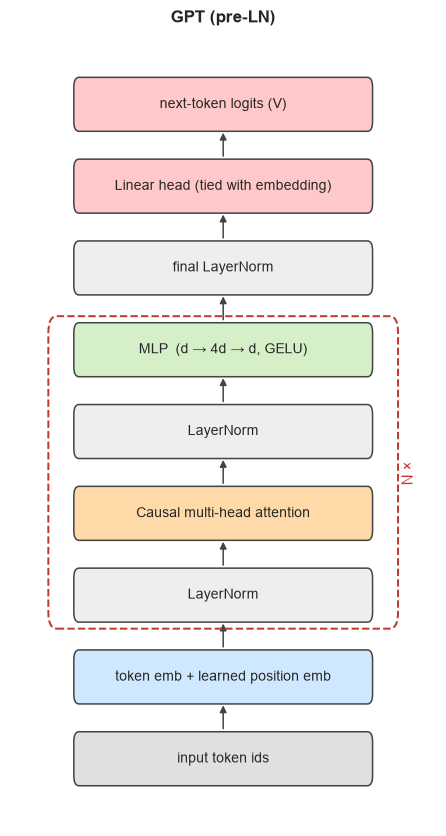

In [2]:
block_diagram([
    ("next-token logits (V)", "out"), ("Linear head (tied with embedding)", "out"), ("final LayerNorm", "norm"),
    ("MLP  (d → 4d → d, GELU)", "ffn*"), ("LayerNorm", "norm*"), ("Causal multi-head attention", "attn*"),
    ("LayerNorm", "norm*"), ("token emb + learned position emb", "embed"), ("input token ids", "other")][::-1],
    title="GPT (pre-LN)", repeat="N ×")

# ## Implementation from scratch

In [3]:
class CausalSelfAttention(nn.Module):
    def __init__(self, d, n_head, max_T):
        super().__init__()
        self.h = n_head; self.qkv = nn.Linear(d, 3 * d); self.proj = nn.Linear(d, d)
        self.register_buffer("mask", torch.tril(torch.ones(max_T, max_T)).bool())
        self.last = None                                            # keep the attention map for plotting

    def forward(self, x):
        B, T, D = x.shape
        q, k, v = [t.view(B, T, self.h, D // self.h).transpose(1, 2) for t in self.qkv(x).split(D, -1)]
        att = (q @ k.transpose(-1, -2)) / math.sqrt(D // self.h)    # (B,H,T,T) similarity of every pair
        att = att.masked_fill(~self.mask[:T, :T], float("-inf")).softmax(-1)  # causal mask: no peeking ahead
        self.last = att.detach()
        return self.proj((att @ v).transpose(1, 2).reshape(B, T, D))

class GPTBlock(nn.Module):
    def __init__(self, d, n_head, max_T):
        super().__init__()
        self.ln1, self.attn = nn.LayerNorm(d), CausalSelfAttention(d, n_head, max_T)
        self.ln2 = nn.LayerNorm(d)
        self.mlp = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d))
    def forward(self, x):
        x = x + self.attn(self.ln1(x))     # residual stream: read -> mix across tokens -> write back
        return x + self.mlp(self.ln2(x))   # per-token computation

class GPT(nn.Module):
    def __init__(self, vocab, d=96, n_head=4, n_layer=3, max_T=128):
        super().__init__()
        self.tok, self.pos = nn.Embedding(vocab, d), nn.Embedding(max_T, d)
        self.blocks = nn.Sequential(*[GPTBlock(d, n_head, max_T) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(d); self.head = nn.Linear(d, vocab, bias=False)
        self.head.weight = self.tok.weight                           # weight tying
        self.apply(lambda m: nn.init.normal_(m.weight, std=0.02) if isinstance(m, (nn.Linear, nn.Embedding)) else None)
    def forward(self, idx):
        x = self.tok(idx) + self.pos(torch.arange(idx.size(1), device=idx.device))
        return self.head(self.ln_f(self.blocks(x)))

model = GPT(V)
print(f"{count_params(model)/1e6:.3f} M parameters")

0.354 M parameters


# ## Layer-by-layer summary (torchinfo)

In [4]:
_ = show_summary(model, input_data=torch.randint(0, V, (1, 64)), depth=2)

Layer (type:depth-idx)                        Input Shape               Output Shape              Param #
GPT                                           [1, 64]                   [1, 64, 65]               --
├─Embedding: 1-1                              [1, 64]                   [1, 64, 96]               6,240
├─Embedding: 1-2                              [64]                      [64, 96]                  12,288
├─Sequential: 1-3                             [1, 64, 96]               [1, 64, 96]               --
│    └─GPTBlock: 2-1                          [1, 64, 96]               [1, 64, 96]               111,840
│    └─GPTBlock: 2-2                          [1, 64, 96]               [1, 64, 96]               111,840
│    └─GPTBlock: 2-3                          [1, 64, 96]               [1, 64, 96]               111,840
├─LayerNorm: 1-4                              [1, 64, 96]               [1, 64, 96]               192
├─Linear: 1-5                                 [1, 64, 96]      

# ## Where do the parameters live? (interactive treemap)

In [5]:
import plotly.express as px, pandas as pd
rows = [(n.split(".")[0] + ("." + n.split(".")[1] if n.startswith("blocks") else ""), n.split(".")[-2] if "." in n else n, p.numel())
        for n, p in model.named_parameters()]
df = pd.DataFrame(rows, columns=["block", "module", "params"])
px.treemap(df, path=["block", "module"], values="params", title="GPT parameter budget").show()

# ## The computation graph (torch.fx → networkx)
# One residual block traced into its dataflow graph (green = module call, orange = function, pink = method).

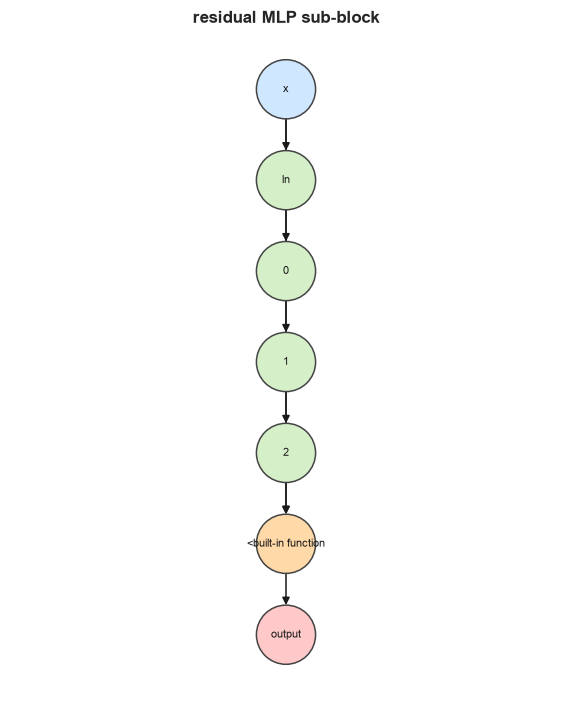

In [6]:
class MiniBlock(nn.Module):               # fx can't trace the dynamic mask slicing, so trace the FFN sub-block
    def __init__(self, d=16):
        super().__init__(); self.ln = nn.LayerNorm(d); self.mlp = nn.Sequential(nn.Linear(d, 4*d), nn.GELU(), nn.Linear(4*d, d))
    def forward(self, x): return x + self.mlp(self.ln(x))
_ = fx_graph_plot(MiniBlock(), figsize=(5, 6), title="residual MLP sub-block")

# ## Train (next-character prediction)

step  200 | train 2.373 | val 2.355 | 7s


step  400 | train 1.987 | val 2.101 | 14s


step  600 | train 1.887 | val 1.967 | 21s


step  800 | train 1.720 | val 1.856 | 28s


step 1000 | train 1.663 | val 1.819 | 40s


step 1200 | train 1.666 | val 1.773 | 47s


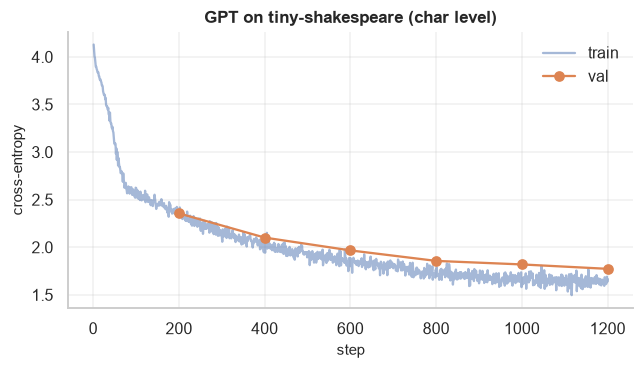

{'name': '01 GPT (decoder-only)',
 'params': 354240,
 'val_loss': 1.7730690598487855,
 'train_loss': 1.6408736526966095}

In [7]:
hist = train_lm(model, train, val, steps=STEPS, block_size=64, batch_size=32, lr=3e-3, device=device, eval_every=200)
plot_losses(hist, "GPT on tiny-shakespeare (char level)")
save_result("01 GPT (decoder-only)", model, hist)

# ## Generate

In [8]:
start = torch.zeros((1, 1), dtype=torch.long, device=device)
print(data["decode"](generate(model, start, 400, temperature=0.8, top_k=10, block_size=128)[0].tolist()))


That merce in thee had here he come
ad body a sith would that is wis wis s s amprammparevelllallon s s arche he mof arellomes in sth th arupendenanin onioss.
I ingrenon han beasthendust, on,
t inathowan ont w m te
An an ano, beeacerne thowed th s, y an yeveallley s yourounofrondegre mp mpouthe mom than n housubunondabunthm y adofar ang.
T hed.
W twhean sth wane oustothise ane t miny t,
Thellllllir


# ## Look inside: what does attention do?
# Rows = the token doing the looking (query), columns = tokens it reads from (key). The upper triangle is empty
# because of the causal mask.

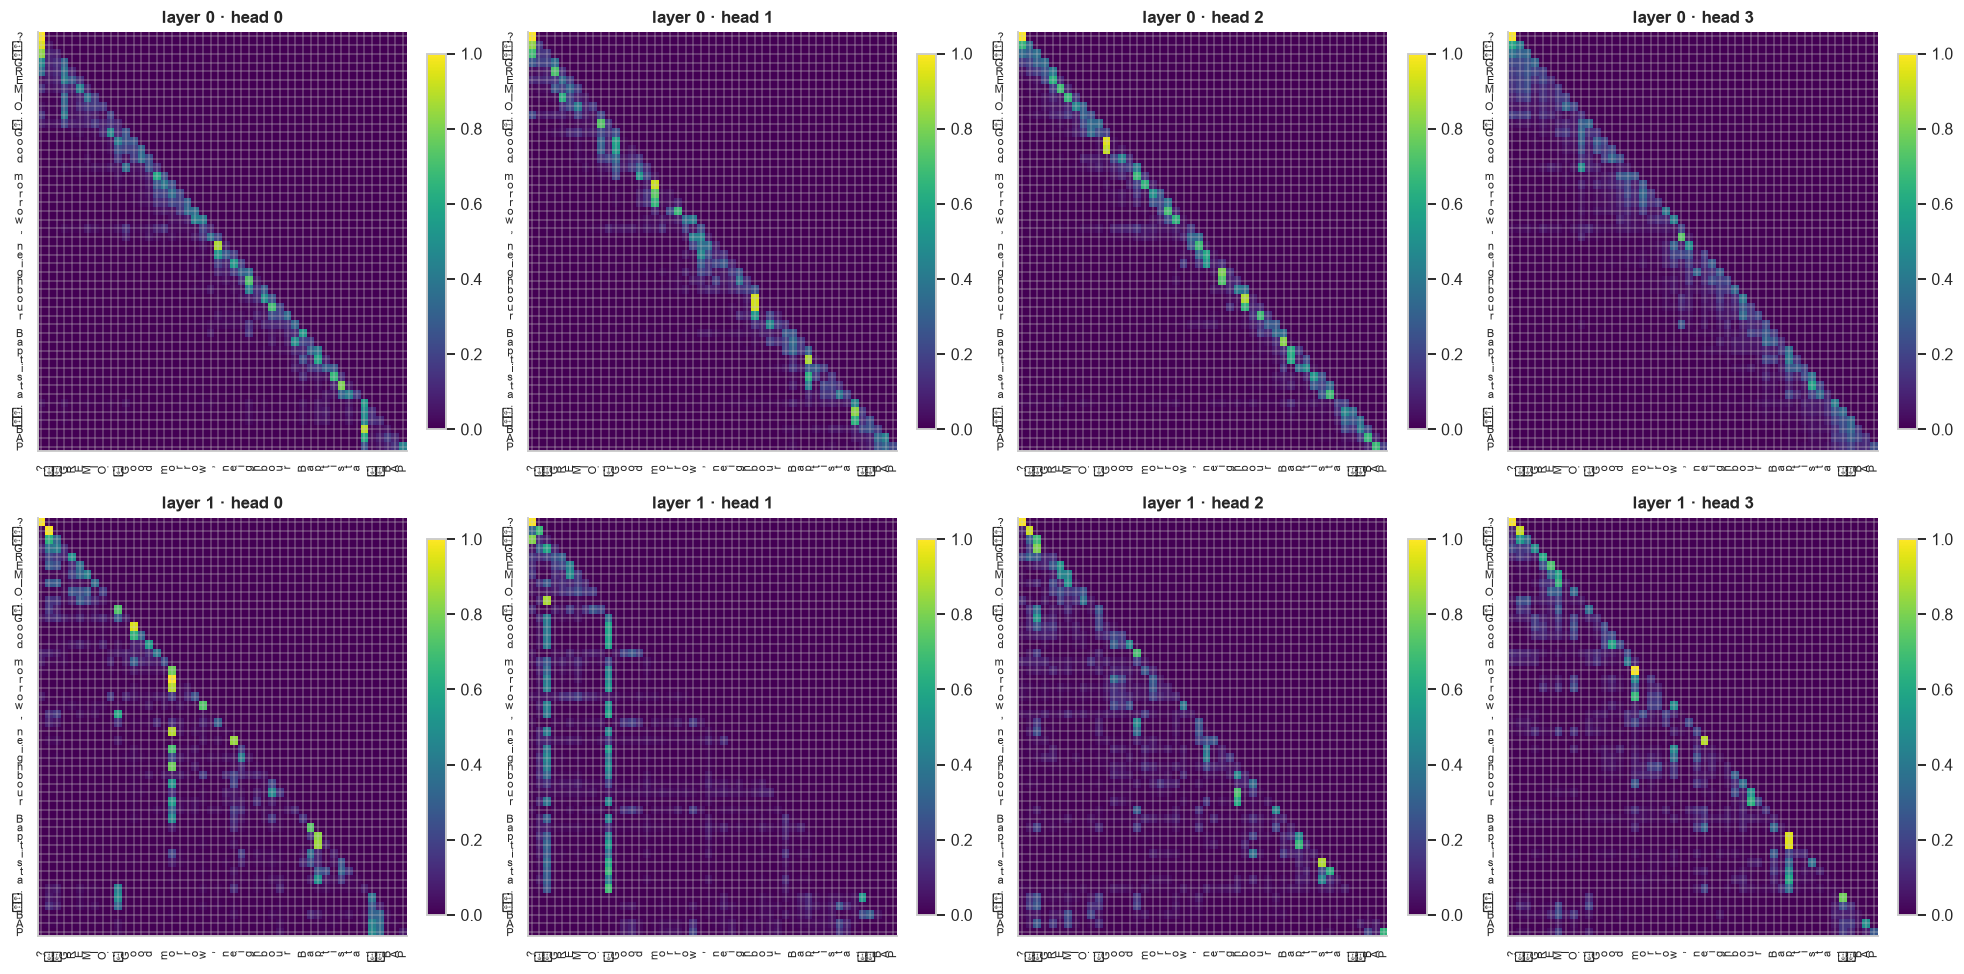

In [9]:
txt = data["decode"](val[:48].tolist()); ids = val[:48][None].to(device)
model.eval(); _ = model(ids); labels = [c if c != "\n" else "⏎" for c in txt]
fig, axs = plt.subplots(2, 4, figsize=(18, 9))
for l, row in enumerate(axs[:2]):
    att = model.blocks[l].attn.last[0].cpu()
    for h, ax in enumerate(row):
        plot_heatmap(att[h], labels, labels, f"layer {l} · head {h}", ax=ax)
plt.tight_layout(); plt.show()

# ## Look inside: position embeddings and the residual stream

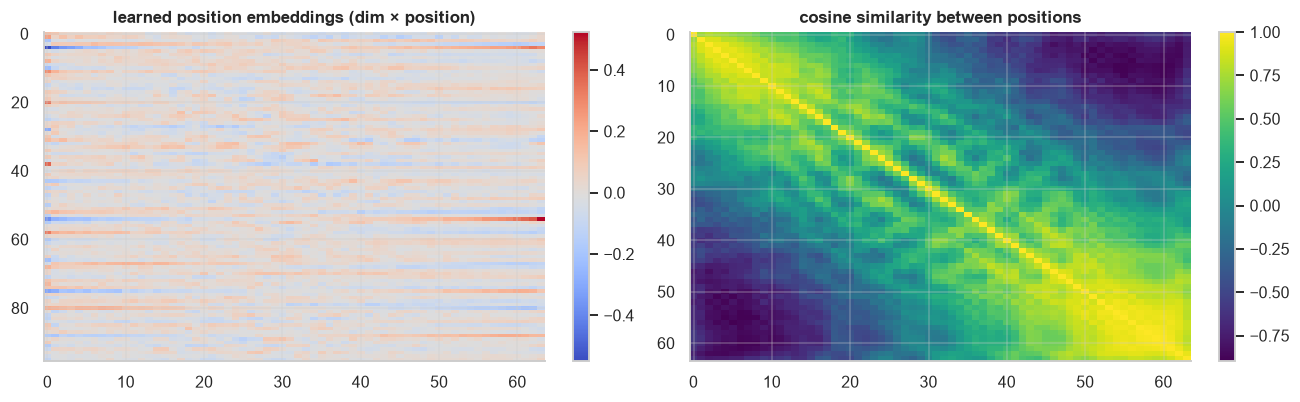

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
pe = model.pos.weight.detach().cpu()[:64]
plot_heatmap(pe.T, title="learned position embeddings (dim × position)", ax=ax[0], cmap="coolwarm")
sim = F.normalize(pe, dim=-1) @ F.normalize(pe, dim=-1).T
plot_heatmap(sim, title="cosine similarity between positions", ax=ax[1])
plt.tight_layout(); plt.show()

# ## Export the graph for Netron
# Open it with `uv run netron artifacts/gpt.onnx` to explore every op interactively.

In [11]:
from pathlib import Path
Path("../artifacts").mkdir(exist_ok=True)
print(export_onnx(model.cpu(), (torch.randint(0, V, (1, 32)),), "../artifacts/gpt.onnx"))

../artifacts/gpt.onnx


---

## Key takeaways

- A Transformer block = *mix across tokens* (attention) + *transform each token* (MLP), glued by residual connections.
- The causal mask turns one sequence into T training examples computed in parallel.
- Attention heads specialise (previous-token, local, repeat patterns) even in a tiny model.

## References

- [Vaswani et al., *Attention Is All You Need* (2017)](https://arxiv.org/abs/1706.03762)
- [Radford et al., *Language Models are Unsupervised Multitask Learners* (GPT-2, 2019)](https://cdn.openai.com/better-language-models/language_models_are_unsupervised_multitask_learners.pdf)
- [Brown et al., *Language Models are Few-Shot Learners* (GPT-3, 2020)](https://arxiv.org/abs/2005.14165)

---
*← previous: `00_data_and_taxonomy`  ·  next: `02_encoder_only_bert` →*